Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



showtext activo: TRUE | fuentes: titulo / cuerpo 

Mujeres con niños/as en el gráfico: 2606 
                        
                         Sin servicio pago Con servicio pago
  Hasta sec. incompleto                801                 7
  Sec. completo                        811                21
  Terc./univ. incompleto               398                19
  Terc./univ. completo                 461                88

Listo: grupo_15_exploratorio.jpg guardado en /content 


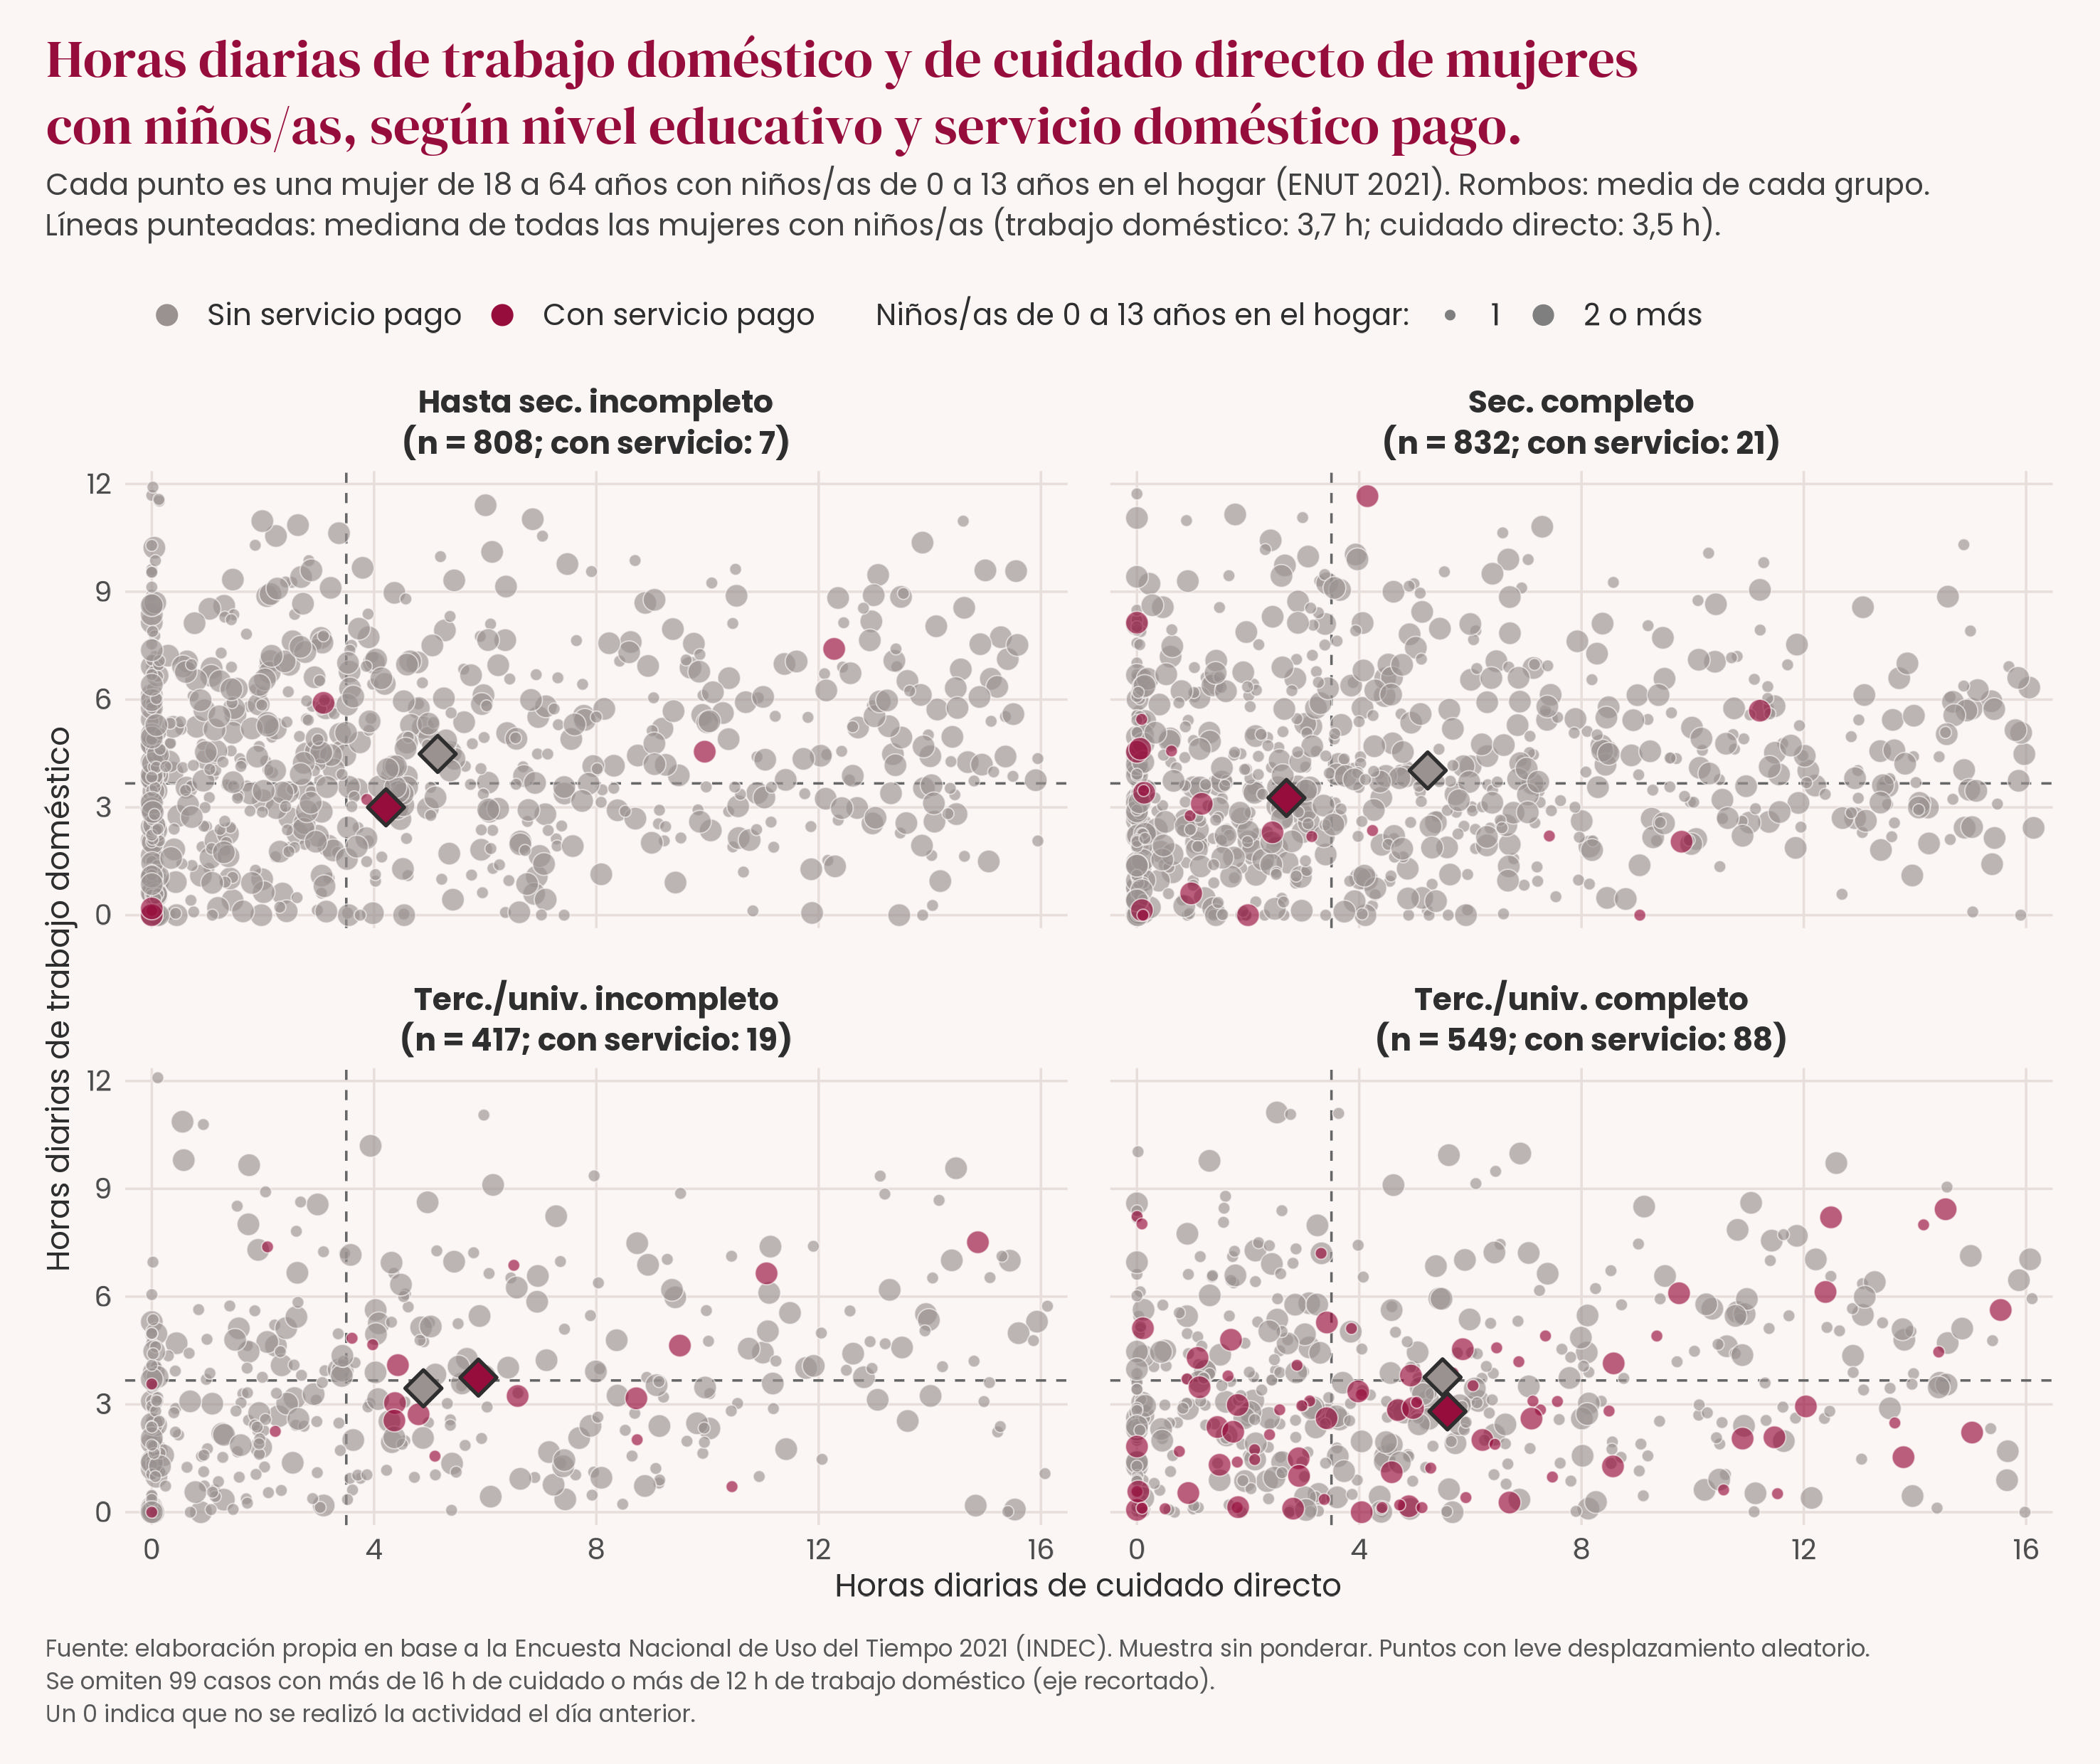

In [11]:
# GRUPO 15 - GRÁFICO EXPLORATORIO (3ra entrega)
# Dispersión de horas de cuidado directo vs. horas de trabajo doméstico, con
# cuadrantes (medianas), color por servicio doméstico pago, tamaño por cantidad
# de niños/as y facetado por nivel educativo.
# Estilo: igual al del gráfico comunicativo (fondo crema, DM Serif Display +
# Poppins, bordó y gris).
# Requisito: tener "enut2021_base.txt" en la carpeta de trabajo de Colab.
# =============================================================================

options(scipen = 999)

# Solo la primera vez en cada sesión de Colab:
install.packages("janitor")

library(tidyverse)
library(janitor)
library(scales)

# -----------------------------------------------------------------------------
# 0. TIPOGRAFÍAS (showtext es opcional: si falla, el gráfico sale igual)
# -----------------------------------------------------------------------------
hay_showtext <- requireNamespace("showtext", quietly = TRUE)
if (!hay_showtext) {
  try({
    system("apt-get -qq update")
    system("apt-get -qq install -y r-cran-showtext")
  }, silent = TRUE)
  hay_showtext <- requireNamespace("showtext", quietly = TRUE)
}
if (!hay_showtext) {
  try({
    install.packages(c("showtext", "sysfonts"))
    hay_showtext <- requireNamespace("showtext", quietly = TRUE)
  }, silent = TRUE)
}

fuente_titulo <- "serif"
fuente_cuerpo <- "sans"
usa_showtext  <- FALSE
dpi_jpg <- 300     # tiene que ser el mismo que el de ggsave()
if (hay_showtext) {
  try({
    library(showtext)
    library(sysfonts)
    font_add_google("DM Serif Display", "titulo")
    font_add_google("Poppins", "cuerpo")
    fuente_titulo <- "titulo"
    fuente_cuerpo <- "cuerpo"
    showtext_opts(dpi = dpi_jpg)
    showtext_auto()
    usa_showtext <- TRUE
  }, silent = TRUE)
}
cat("showtext activo:", usa_showtext, "| fuentes:", fuente_titulo, "/", fuente_cuerpo, "\n")

# -----------------------------------------------------------------------------
# 1. DATOS (misma muestra que el notebook: enut_clean, N = 6.046)
# -----------------------------------------------------------------------------
enut_raw <- read_delim("enut2021_base.txt", delim = "|", show_col_types = FALSE) |>
  clean_names()

niveles_orig <- c("1. Hasta Sec. Incompleto", "2. Secundario Completo",
                  "3. Terciario/Univ. Incompleto", "4. Terciario/Univ. Completo")
niveles_corto <- c("Hasta sec. incompleto", "Sec. completo",
                   "Terc./univ. incompleto", "Terc./univ. completo")

enut_clean <- enut_raw |>
  filter(
    sexo_sel == 1,
    edad_sel >= 18 & edad_sel <= 64,
    !nivel_educativo_sel %in% c(8, 99, NA)
  ) |>
  mutate(
    hs_domestico = tcs_grupo_domestico / 60,
    hs_cuidado   = tcs_grupo_cuidado / 60,
    educacion_4cat = case_when(
      nivel_educativo_sel %in% c(1, 2, 3, 4) ~ niveles_orig[1],
      nivel_educativo_sel == 5                ~ niveles_orig[2],
      nivel_educativo_sel == 6                ~ niveles_orig[3],
      nivel_educativo_sel == 7                ~ niveles_orig[4]
    ),
    servicio_pago = case_when(
      t_domestico_pago == 1 ~ "Con servicio pago",
      t_domestico_pago == 2 ~ "Sin servicio pago",
      TRUE                  ~ NA_character_
    )
  )

# Muestra del gráfico: mujeres con niños/as de 0 a 13 años en el hogar
con_ninos <- enut_clean |>
  filter(cant_personashasta13 > 0, !is.na(servicio_pago)) |>
  mutate(
    nivel = factor(educacion_4cat, levels = niveles_orig, labels = niveles_corto),
    servicio_pago = factor(servicio_pago,
                           levels = c("Sin servicio pago", "Con servicio pago")),
    ninos = pmin(cant_personashasta13, 2)      # 1 = "1 niño/a", 2 = "2 o más" (igual que el comunicativo)
  )

# CONTROL: debería dar 2606 mujeres y, con servicio por nivel, 7 / 21 / 19 / 88
cat("\nMujeres con niños/as en el gráfico:", nrow(con_ninos), "\n")
print(table(con_ninos$nivel, con_ninos$servicio_pago))

# -----------------------------------------------------------------------------
# 2. DATOS AUXILIARES
# -----------------------------------------------------------------------------
med_dom <- median(con_ninos$hs_domestico)
med_cui <- median(con_ninos$hs_cuidado)

fmt_n   <- function(x) format(x, big.mark = ".", decimal.mark = ",", trim = TRUE)

etiquetas <- con_ninos |>
  group_by(nivel) |>
  summarise(n = n(),
            n_serv = sum(servicio_pago == "Con servicio pago"),
            .groups = "drop") |>
  mutate(panel = paste0(nivel, "\n(n = ", fmt_n(n), "; con servicio: ", n_serv, ")"))

con_ninos <- con_ninos |>
  left_join(etiquetas, by = "nivel") |>
  mutate(panel = factor(panel, levels = etiquetas$panel))

# Media de cada grupo (rombos), calculada con todas las mujeres
medias <- con_ninos |>
  group_by(panel, servicio_pago) |>
  summarise(dom = mean(hs_domestico), cui = mean(hs_cuidado), .groups = "drop")

# Casos fuera de los ejes (se avisa en el pie)
n_fuera <- sum(con_ninos$hs_cuidado > 16 | con_ninos$hs_domestico > 12)

# Datos a graficar: sin casos fuera de los ejes y con leve jitter (sin bajar de 0)
set.seed(123)
datos_plot <- con_ninos |>
  filter(hs_cuidado <= 16, hs_domestico <= 12) |>
  mutate(
    x = pmax(hs_cuidado   + runif(n(), -0.15, 0.15), 0),
    y = pmax(hs_domestico + runif(n(), -0.15, 0.15), 0)
  ) |>
  arrange(servicio_pago)      # "Con servicio" queda dibujado encima

# -----------------------------------------------------------------------------
# 3. ESTILO (el mismo del gráfico comunicativo)
# -----------------------------------------------------------------------------
col_con   <- "#960D3C"   # bordó
col_sin   <- "#9A9290"   # gris
col_fondo <- "#FBF6F4"   # crema
col_grid  <- "#E7DEDB"
col_texto <- "#2E2E2E"

# -----------------------------------------------------------------------------
# 4. GRÁFICO
# -----------------------------------------------------------------------------
g_expl <- ggplot() +

  # medianas: dividen cada panel en cuadrantes
  geom_vline(xintercept = med_cui, linetype = "dashed",
             color = "gray40", linewidth = 0.4) +
  geom_hline(yintercept = med_dom, linetype = "dashed",
             color = "gray40", linewidth = 0.4) +

  # una mujer por punto: color = servicio pago, tamaño = cantidad de niños/as
  geom_point(data = datos_plot,
             aes(x = x, y = y, fill = servicio_pago, size = ninos),
             shape = 21, color = col_fondo, stroke = 0.3, alpha = 0.65) +

  # media de cada grupo (rombos)
  geom_point(data = medias, aes(x = cui, y = dom, fill = servicio_pago),
             shape = 23, size = 4, color = col_texto, stroke = 0.9,
             show.legend = FALSE) +

  facet_wrap(~ panel, nrow = 2) +

  scale_fill_manual(values = c("Sin servicio pago" = col_sin,
                               "Con servicio pago" = col_con)) +
  scale_size_continuous(range = c(1.7, 3.4), breaks = 1:2,
                        labels = c("1", "2 o más")) +
  scale_x_continuous(breaks = seq(0, 16, 4),
                     labels = label_number(decimal.mark = ","),
                     expand = expansion(mult = 0.03)) +
  scale_y_continuous(breaks = seq(0, 12, 3),
                     labels = label_number(decimal.mark = ","),
                     expand = expansion(mult = 0.03)) +
  coord_cartesian(xlim = c(0, 16), ylim = c(0, 12)) +

  guides(
    fill = guide_legend(order = 1,
                        override.aes = list(shape = 21, size = 3.5,
                                            alpha = 1, color = col_fondo)),
    size = guide_legend(order = 2,
                        override.aes = list(shape = 21, fill = "gray50",
                                            color = col_fondo, alpha = 1))
  ) +

  labs(
    title    = str_wrap(paste0(
      "Horas diarias de trabajo doméstico y de cuidado directo de mujeres con niños/as, ",
      "según nivel educativo y servicio doméstico pago."), width = 66),
    subtitle = paste0(
      "Cada punto es una mujer de 18 a 64 años con niños/as de 0 a 13 años en el hogar (ENUT 2021). ",
      "Rombos: media de cada grupo.\n",
      "Líneas punteadas: mediana de todas las mujeres con niños/as (trabajo doméstico: ",
      format(round(med_dom, 1), decimal.mark = ","), " h; cuidado directo: ",
      format(round(med_cui, 1), decimal.mark = ","), " h)."),
    x       = "Horas diarias de cuidado directo",
    y       = "Horas diarias de trabajo doméstico",
    fill    = NULL,
    size    = "Niños/as de 0 a 13 años en el hogar:",
    caption = paste0(
      "Fuente: elaboración propia en base a la Encuesta Nacional de Uso del Tiempo 2021 (INDEC). ",
      "Muestra sin ponderar. Puntos con leve desplazamiento aleatorio.\n",
      "Se omiten ", n_fuera, " casos con más de 16 h de cuidado o más de 12 h de trabajo doméstico (eje recortado).\n",
      "Un 0 indica que no se realizó la actividad el día anterior.")
  ) +

  theme_minimal(base_size = 11, base_family = fuente_cuerpo) +
  theme(
    plot.background       = element_rect(fill = col_fondo, color = NA),
    panel.background      = element_rect(fill = col_fondo, color = NA),
    plot.title.position   = "plot",
    plot.caption.position = "plot",
    plot.title    = element_text(family = fuente_titulo, size = 18, color = col_con,
                                 lineheight = 1.05, margin = margin(b = 6)),
    plot.subtitle = element_text(size = 10, color = "grey25", lineheight = 1.15,
                                 margin = margin(b = 10)),
    plot.caption  = element_text(size = 8, color = "grey35", hjust = 0,
                                 lineheight = 1.15, margin = margin(t = 12)),
    plot.margin   = margin(14, 16, 12, 16),
    strip.text    = element_text(face = "bold", size = 10.5, color = col_texto,
                                 lineheight = 1.1),
    axis.title    = element_text(size = 10.5, color = col_texto),
    axis.text     = element_text(size = 9.5, color = "grey30"),
    panel.grid.minor = element_blank(),
    panel.grid.major = element_line(color = col_grid, linewidth = 0.4),
    panel.spacing = unit(1, "lines"),
    legend.position      = "top",
    legend.justification = "left",
    legend.title = element_text(size = 10, color = col_texto),
    legend.text  = element_text(size = 10, color = col_texto),
    legend.key   = element_rect(fill = NA, color = NA),
    legend.background = element_rect(fill = NA, color = NA),
    legend.box.spacing = unit(0.2, "cm")
  )

# -----------------------------------------------------------------------------
# 5. EXPORTAR (25 cm de ancho, 21 cm de alto, 300 dpi)
# Si showtext no está activo y ragg está instalado, se usa ragg.
# -----------------------------------------------------------------------------
dispositivo <- if (!usa_showtext && requireNamespace("ragg", quietly = TRUE)) {
  ragg::agg_jpeg
} else {
  NULL
}

ggsave("grupo_15_exploratorio.jpg", plot = g_expl,
       width = 25, height = 21, units = "cm", dpi = dpi_jpg,
       device = dispositivo)

cat("\nListo: grupo_15_exploratorio.jpg guardado en", getwd(), "\n")

# Vista previa en Colab
IRdisplay::display_jpeg(file = "grupo_15_exploratorio.jpg", width = 900)


In [10]:
# GRUPO 15 - GRÁFICO COMUNICATIVO (3ra entrega) - Opción B
# Jornada de trabajo no remunerado (doméstico + cuidado directo) según la edad
# de la mujer y la cantidad de niños/as de 0 a 13 años en el hogar.
# Requisito: tener "enut2021_base.txt" en la carpeta de trabajo de Colab.
# =============================================================================

options(scipen = 999)

# Solo la primera vez en cada sesión de Colab:
install.packages("janitor")

library(tidyverse)
library(janitor)
library(scales)

# Las fuentes son opcionales: si showtext no se instala, el gráfico se genera
# igual (con tipografía genérica) y el script avisa.
hay_showtext <- FALSE
try({
  install.packages(c("showtext", "sysfonts"))
  library(showtext)
  library(sysfonts)
  hay_showtext <- TRUE
}, silent = TRUE)
cat("showtext disponible:", hay_showtext, "\n")

fuente_titulo <- "serif"
fuente_cuerpo <- "sans"
if (hay_showtext) {
  try({
    font_add_google("DM Serif Display", "titulo")
    font_add_google("Poppins", "cuerpo")
    fuente_titulo <- "titulo"
    fuente_cuerpo <- "cuerpo"
  }, silent = TRUE)
  try({
    showtext_auto()
    showtext_opts(dpi = 300)
  }, silent = TRUE)
}
cat("Fuentes en uso:", fuente_titulo, "/", fuente_cuerpo, "\n")

# Interruptor: ¿mostrar cada mujer como un punto tenue de fondo?
mostrar_puntos <- TRUE

# -----------------------------------------------------------------------------
# 1. DATOS (mismo filtro que la regresión del TP2: n = 6.042)
# -----------------------------------------------------------------------------
enut_raw <- read_delim("enut2021_base.txt", delim = "|") |>
  clean_names()

niveles_ninos <- c("Sin niños/as", "1 niño/a", "2 o más niños/as")

base <- enut_raw |>
  filter(
    sexo_sel == 1,
    edad_sel >= 18, edad_sel <= 64,
    !(nivel_educativo_sel %in% c(8, 9, 99)),
    t_domestico_pago %in% c(1, 2)
  ) |>
  mutate(
    hs_total = (tcs_grupo_domestico + tcs_grupo_cuidado) / 60,
    ninos = case_when(
      cant_personashasta13 == 0 ~ niveles_ninos[1],
      cant_personashasta13 == 1 ~ niveles_ninos[2],
      cant_personashasta13 >= 2 ~ niveles_ninos[3]
    ),
    ninos = factor(ninos, levels = niveles_ninos)
  )

# -----------------------------------------------------------------------------
# 2. CONTROL: miren estos números antes de fijar el título
# -----------------------------------------------------------------------------
resumen <- base |>
  group_by(ninos) |>
  summarise(n = n(),
            media_hs = mean(hs_total),
            mediana_hs = median(hs_total),
            edad_p025 = quantile(edad_sel, 0.025),
            edad_p975 = quantile(edad_sel, 0.975),
            .groups = "drop")
cat("\nTamaño de la muestra (debería ser 6042):", nrow(base), "\n")
print(resumen)
y_max <- 13   # tope del eje vertical (horas por día)
cat("\n% de mujeres por encima del corte del eje (>", y_max, "h):",
    round(mean(base$hs_total > y_max) * 100, 2), "\n")

m0 <- resumen$media_hs[resumen$ninos == niveles_ninos[1]]
m2 <- resumen$media_hs[resumen$ninos == niveles_ninos[3]]
fmt_dec <- function(x) format(round(x, 1), decimal.mark = ",", nsmall = 1)
fmt_n   <- function(x) format(x, big.mark = ".", decimal.mark = ",", trim = TRUE)

# -----------------------------------------------------------------------------
# 3. CURVAS SUAVIZADAS (loess) con banda de confianza al 95 %
# Cada grupo se dibuja solo en el rango de edades que cubre su 95 % central,
# para no inventar curvas donde casi no hay mujeres.
# -----------------------------------------------------------------------------
suavizar <- function(d) {
  m <- loess(hs_total ~ edad_sel, data = d, span = 0.75, degree = 2)
  rango <- seq(ceiling(as.numeric(quantile(d$edad_sel, 0.025))),
               floor(as.numeric(quantile(d$edad_sel, 0.975))))
  p <- predict(m, newdata = data.frame(edad_sel = rango), se = TRUE)
  tibble(edad_sel = rango,
         fit = p$fit,
         lo  = p$fit - 1.96 * p$se.fit,
         hi  = p$fit + 1.96 * p$se.fit)
}

curvas <- base |>
  group_by(ninos) |>
  group_modify(~ suavizar(.x)) |>
  ungroup()

# Punto final de cada curva (para las etiquetas directas) y pico del grupo 2+
fin <- curvas |>
  group_by(ninos) |>
  slice_max(edad_sel, n = 1) |>
  ungroup() |>
  left_join(resumen |> select(ninos, n), by = "ninos") |>
  mutate(etiqueta = paste0(ninos, " (n = ", fmt_n(n), ")")) |>
  arrange(fit)

# Cada etiqueta va pegada al final de su curva. Si dos quedan demasiado juntas
# se separan lo mínimo en vertical para que no se pisen.
sep_min <- 1.3                      # separación mínima entre etiquetas (en horas)
fin$y_lab <- fin$fit
for (i in seq_len(nrow(fin))[-1]) {
  fin$y_lab[i] <- max(fin$fit[i], fin$y_lab[i - 1] + sep_min)
}

# Pico de la curva destacada y brecha con "sin niños/as" a esa misma edad
pico <- curvas |>
  filter(ninos == niveles_ninos[3]) |>
  slice_max(fit, n = 1)
f0_pico <- curvas |>
  filter(ninos == niveles_ninos[1], edad_sel == pico$edad_sel) |>
  pull(fit)
brecha_pico <- pico$fit - f0_pico
cat("\nA los", pico$edad_sel, "años: 2 o más niños/as =", round(pico$fit, 1),
    "h; sin niños/as =", round(f0_pico, 1), "h; brecha =", round(brecha_pico, 1), "h\n")

# Control del título ("a cualquier edad"): la brecha mínima entre curvas
# debe ser positiva para que la frase sea cierta.
anchas <- curvas |> select(ninos, edad_sel, fit) |>
  pivot_wider(names_from = ninos, values_from = fit)
cat("Brecha mínima '2 o más' vs 'sin niños':",
    round(min(anchas[[niveles_ninos[3]]] - anchas[[niveles_ninos[1]]], na.rm = TRUE), 2), "h\n")
cat("Brecha mínima '1 niño' vs 'sin niños':",
    round(min(anchas[[niveles_ninos[2]]] - anchas[[niveles_ninos[1]]], na.rm = TRUE), 2), "h\n")

# -----------------------------------------------------------------------------
# 4. ESTILO (paleta de la presentación: bordó + crema + grises)
# -----------------------------------------------------------------------------
col_con   <- "#960D3C"   # bordó: el grupo que queremos destacar
col_fondo <- "#FBF6F4"   # crema de las tarjetas de la ppt
col_grid  <- "#E7DEDB"
col_texto <- "#2E2E2E"

colores  <- c("Sin niños/as"      = "#9A9290",
              "1 niño/a"          = "#6F6F6F",
              "2 o más niños/as"  = col_con)
grosores <- c("Sin niños/as" = 0.9, "1 niño/a" = 0.9, "2 o más niños/as" = 1.5)

# Marcas del eje de edad: cada 10 años, pero reemplazando la que quede a menos
# de 4 años del máximo por la edad exacta del máximo (resaltada en bordó).
breaks_x <- seq(20, 60, by = 10)
breaks_x <- sort(c(breaks_x[abs(breaks_x - pico$edad_sel) >= 4], pico$edad_sel))
cols_x   <- ifelse(breaks_x == pico$edad_sel, col_con, "grey30")
faces_x  <- ifelse(breaks_x == pico$edad_sel, "bold", "plain")

# -----------------------------------------------------------------------------
# 5. GRÁFICO
# -----------------------------------------------------------------------------
g <- ggplot()

if (mostrar_puntos) {
  g <- g + geom_point(
    data = base |> filter(hs_total <= y_max),
    aes(x = edad_sel, y = hs_total, color = ninos),
    position = position_jitter(width = 0.4, height = 0, seed = 1),
    size = 0.5, alpha = 0.07, stroke = 0
  )
}

g <- g +
  geom_line(data = curvas,
            aes(x = edad_sel, y = fit, color = ninos, linewidth = ninos),
            lineend = "round") +
  scale_color_manual(values = colores, guide = "none") +
  scale_linewidth_manual(values = grosores, guide = "none") +
  # Etiquetas pegadas al final de cada curva, en el color de la curva
  geom_text(data = fin,
            aes(x = edad_sel + 0.8, y = y_lab, label = etiqueta, color = ninos),
            hjust = 0, vjust = 0.5, fontface = "bold", size = 3.9,
            family = fuente_cuerpo) +
  # Línea punteada sutil: baja desde la curva "sin niños/as" hasta el eje,
  # para que se vea la edad en que ocurre el máximo (la flecha cubre el tramo de arriba)
  annotate("segment",
           x = pico$edad_sel, xend = pico$edad_sel,
           y = 0, yend = f0_pico - 0.3,
           linetype = "dotted", linewidth = 0.5, color = col_con, alpha = 0.6) +
  # Flecha de la brecha entre la curva destacada y "sin niños/as"
  annotate("segment",
           x = pico$edad_sel, xend = pico$edad_sel,
           y = f0_pico + 0.4, yend = pico$fit - 0.4,
           arrow = arrow(length = unit(0.14, "cm"), ends = "both"),
           linewidth = 0.45, color = col_texto) +
  # Punto y número en el máximo de la curva destacada
  annotate("point", x = pico$edad_sel, y = pico$fit,
           shape = 21, size = 3, stroke = 0.9,
           fill = col_con, color = col_fondo) +
  annotate("text", x = pico$edad_sel, y = pico$fit + 0.4,
           hjust = 0.5, vjust = 0,
           label = fmt_dec(pico$fit),
           color = col_con, size = 4.6, fontface = "bold",
           family = fuente_cuerpo) +
  # Punto y número en la curva "sin niños/as", a la misma edad
  annotate("point", x = pico$edad_sel, y = f0_pico,
           shape = 21, size = 3, stroke = 0.9,
           fill = colores[["Sin niños/as"]], color = col_fondo) +
  annotate("text", x = pico$edad_sel + 0.9, y = f0_pico - 0.2,
           hjust = 0, vjust = 1,
           label = fmt_dec(f0_pico),
           color = "#7D7573", size = 4.6, fontface = "bold",
           family = fuente_cuerpo) +
  annotate("text",
           x = pico$edad_sel + 0.8, y = f0_pico + 0.42 * (pico$fit - f0_pico),
           hjust = 0, vjust = 0.5,
           label = paste0(fmt_dec(brecha_pico), " h por día\nde diferencia"),
           color = col_texto, size = 3.7, fontface = "bold",
           lineheight = 0.95, family = fuente_cuerpo) +
  scale_x_continuous(breaks = breaks_x) +
  scale_y_continuous(breaks = seq(0, 12, by = 4)) +
  coord_cartesian(xlim = c(18, 79), ylim = c(0, y_max + 0.2), expand = FALSE) +
  labs(x = "Edad de la mujer (años)",
       y = "Horas por día de trabajo no remunerado\n(doméstico + cuidado directo)") +
  theme_minimal(base_size = 11, base_family = fuente_cuerpo) +
  theme(
    plot.background    = element_rect(fill = col_fondo, color = NA),
    panel.background   = element_rect(fill = col_fondo, color = NA),
    panel.grid.minor   = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(color = col_grid, linewidth = 0.4),
    axis.title         = element_text(color = col_texto, size = 10.5),
    axis.title.y       = element_text(color = col_texto, size = 10.5,
                                      margin = margin(r = 10)),
    axis.text          = element_text(color = "grey30", size = 10),
    axis.text.x        = element_text(color = cols_x, face = faces_x, size = 10),
    plot.title.position   = "plot",
    plot.caption.position = "plot",
    plot.margin        = margin(14, 16, 12, 16)
  )

# -----------------------------------------------------------------------------
# 6. TÍTULO, BAJADA Y FUENTE
# El título usa los números calculados arriba. REVISEN que coincida con lo
# que se ve (por ejemplo, que la brecha se mantenga en todas las edades).
# -----------------------------------------------------------------------------
titulo <- str_wrap(
  "Con niños/as en el hogar, las mujeres hacen más trabajo no remunerado a todas las edades.",
  width = 62)

bajada_1 <- str_wrap(paste0(
  "Tendencia de las horas diarias de trabajo doméstico y de cuidado directo según la edad, ",
  "por cantidad de niños/as de 0 a 13 años en el hogar."),
  width = 115)

bajada_2 <- str_wrap(paste0(
  "Según la tendencia, a los ", pico$edad_sel, " años las mujeres con 2 o más niños/as dedican ",
  fmt_dec(brecha_pico), " horas más por día que las que no viven con niños/as (",
  fmt_dec(pico$fit), " h contra ", fmt_dec(f0_pico), " h). ",
  "Mujeres de 18 a 64 años, de aglomerados urbanos de Argentina, 2021."),
  width = 115)

bajada <- paste0(bajada_1, "\n", bajada_2)

nota <- str_wrap(paste0(
  "Fuente: elaboración propia en base a la Encuesta Nacional de Uso del Tiempo 2021 (INDEC). ",
  "Muestra sin ponderar: ", fmt_n(nrow(base)), " mujeres. Tendencias suavizadas (loess); ",
  "cada grupo se muestra en las edades que cubren su 95 % central. ",
  "Eje vertical cortado en ", y_max, " h. Asociación descriptiva, no una causa."),
  width = 140)

grafico <- g +
  labs(title = titulo, subtitle = bajada, caption = nota) +
  theme(
    plot.title    = element_text(family = fuente_titulo, size = 18.5, color = col_con,
                                 lineheight = 1.05, margin = margin(b = 6)),
    plot.subtitle = element_text(family = fuente_cuerpo, size = 10, color = "grey25",
                                 lineheight = 1.15, margin = margin(b = 12)),
    plot.caption  = element_text(family = fuente_cuerpo, size = 8, color = "grey35",
                                 hjust = 0, lineheight = 1.15, margin = margin(t = 12))
  )

# -----------------------------------------------------------------------------
# 7. EXPORTAR (300 dpi, 24 cm de ancho)
# -----------------------------------------------------------------------------
ggsave(
  filename = "grupo_15_comunicativo.jpg",
  plot     = grafico,
  width    = 24,
  height   = 15.5,
  units    = "cm",
  dpi      = 300,
  quality  = 95
)

cat("\nListo: grupo_15_comunicativo.jpg guardado en", getwd(), "\n")


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



showtext disponible: TRUE 
Fuentes en uso: titulo / cuerpo 


Rows: 14350 Columns: 327
── Column specification ────────────────────────────────────────────────────────
Delimiter: "|"
dbl (326): ID, WHOG, WPER, REGION, N_MIEMBRO, BHCV01, BHCV02, BHCV03, BHCV04...
lgl   (1): BHDC01_08_SEL

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.



Tamaño de la muestra (debería ser 6042): 6042 
# A tibble: 3 × 6
  ninos                n media_hs mediana_hs edad_p025 edad_p975
  <fct>            <int>    <dbl>      <dbl>     <dbl>     <dbl>
1 Sin niños/as      3436     3.57       3           19      64  
2 1 niño/a          1390     8.09       7           19      60  
3 2 o más niños/as  1216    10.4        9.17        19      57.6

% de mujeres por encima del corte del eje (> 13 h): 11.54 

A los 32 años: 2 o más niños/as = 11.7 h; sin niños/as = 2.7 h; brecha = 9 h
Brecha mínima '2 o más' vs 'sin niños': 3.26 h
Brecha mínima '1 niño' vs 'sin niños': 2.36 h


Warning message:
“Vectorized input to `element_text()` is not officially supported.
ℹ Results may be unexpected or may change in future versions of ggplot2.”



Listo: grupo_15_comunicativo.jpg guardado en /content 
